# Bayesian House Price Prediction and Uncertainty Quantification

## One model, three computational methods

This notebook fits a conjugate Bayesian linear regression model to the UCI Real Estate Valuation dataset. It compares analytical calculations, direct posterior sampling, and Gibbs MCMC using the **same data, likelihood, and prior**.

The goals are to estimate regression coefficients, quantify uncertainty, predict held-out house prices, and check that the three computational methods give consistent results.

Each section explains its objective, the relevant formulas, and common interpretation pitfalls. The saved outputs allow the analysis to be reviewed before rerunning it.

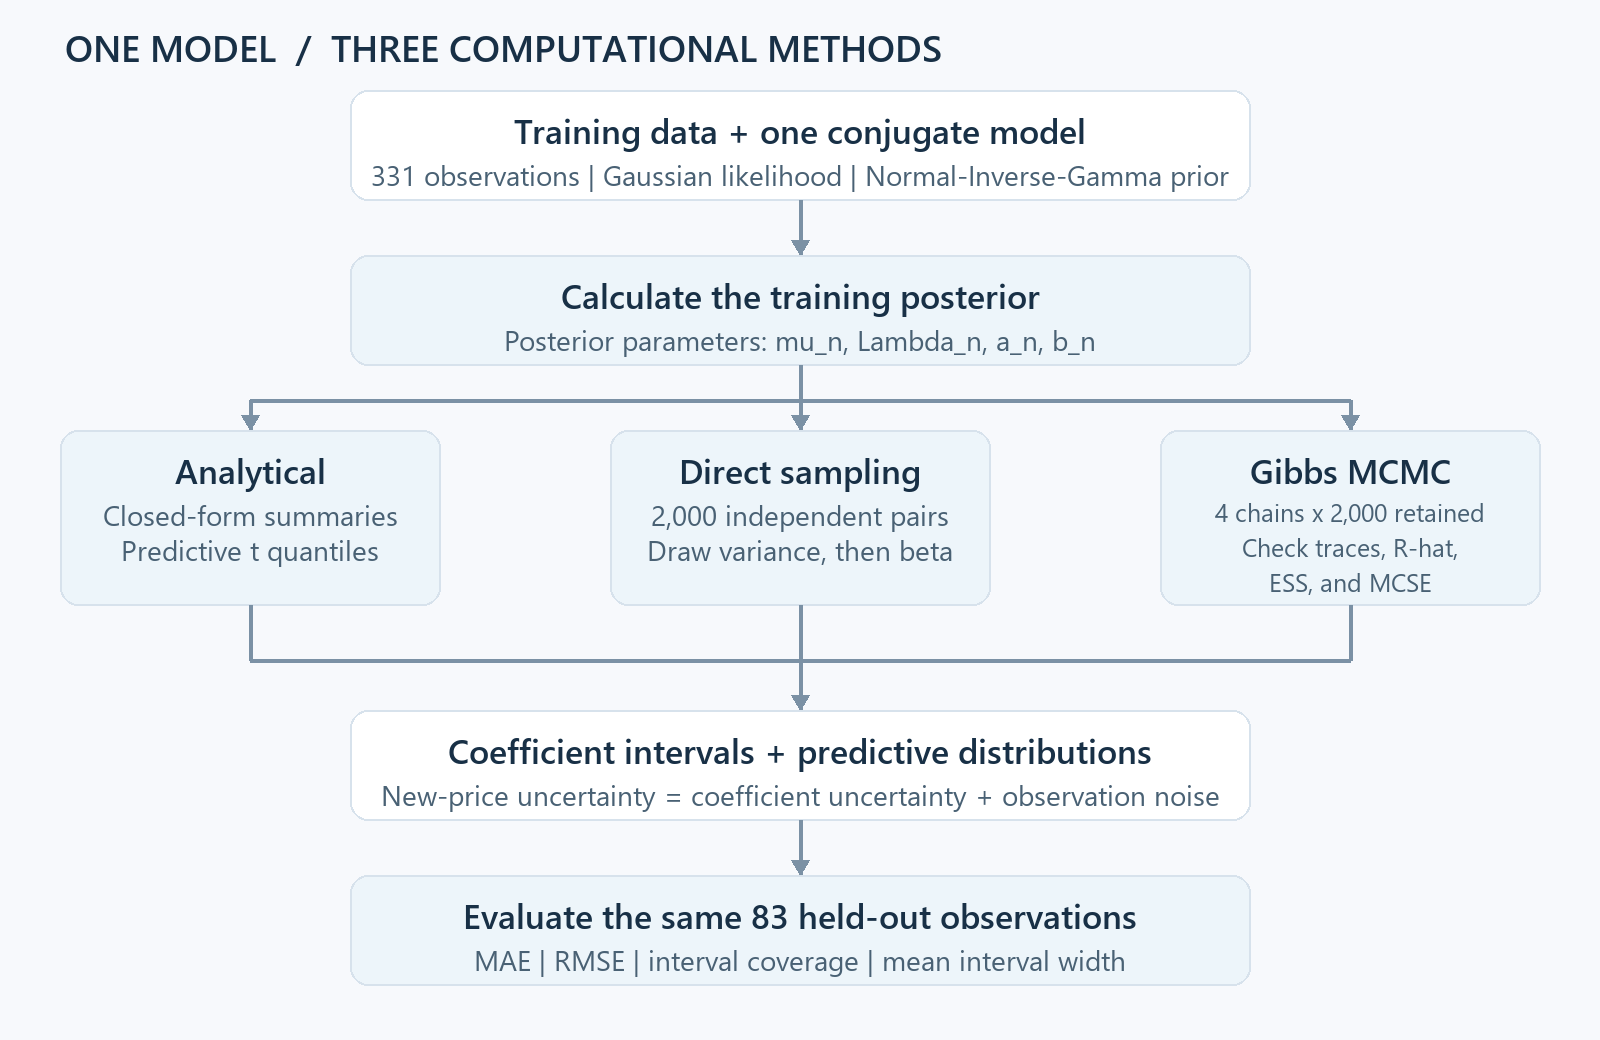


## Reading and execution guide

| Step | Question answered |
| --- | --- |
| [1. Data preparation](#step-1) | Which variables are used, and how are training and test data separated? |
| [2. Design matrix](#step-2) | Why add an intercept, and why are there four coefficients? |
| [3. Posterior updates](#step-3) | How do the prior and likelihood determine the posterior parameters? |
| [4. Direct posterior sampling](#step-4) | How can samples be drawn from the known joint posterior? |
| [5. Coefficient credible intervals](#step-5) | Why are marginal coefficient intervals based on a Student t distribution? |
| [6. Posterior prediction](#step-6) | How are a new property's predictive mean and interval calculated? |
| [7. Point prediction evaluation](#step-7) | How accurate are the predictions relative to a simple baseline? |
| [8. Predictive interval evaluation](#step-8) | Are intervals covering observations, and why are they wide? |
| [9. Gibbs sampling](#step-9) | How do the full conditional updates and their implementation work? |
| [10. MCMC diagnostics](#step-10) | What do trace plots, R-hat, ESS, and MCSE tell us? |
| [11. Method comparison](#step-11) | Do the three methods agree under identical evaluation rules? |

**How to run:** use a Python notebook environment such as Jupyter or Colab, and run code cells from top to bottom. The notebook uses NumPy, pandas, SciPy, scikit-learn, Matplotlib, ucimlrepo, arviz-base, and arviz-stats. The original package-installation cells are retained; a fresh environment may need the other packages installed as well. Data retrieval requires internet access.

**How to read formulas:** throughout the inference steps, `X` and `y` in mathematical expressions mean the **training** design matrix and target vector. $D=(X,y)$ denotes the training data. Test observations are used for evaluation, not posterior fitting.

**Formula origins:** "Report" identifies formulas in Zijie Wang's accompanying report. "Supplementary derivation" identifies consequences of the same model that are explained here, including the marginal coefficient t distribution and Gibbs conditionals. "Numerical implementation" explains how a formula is evaluated in code. References are listed at the end.


<a id="step-1"></a>
## Step 1 - Prepare the data and train/test split

### 1.1 Set up data access

**Objective.** Install the package used to retrieve the dataset from UCI. This is an environment setup step; it does not fit a model.


In [1]:
%pip install ucimlrepo

### 1.2 Select the predictors and target

**Objective.** Retrieve dataset 477 and select the three predictors used throughout this notebook.

| Role | Variable | Unit |
| --- | --- | --- |
| Predictor | House age | Years |
| Predictor | Distance to the nearest MRT station | Meters |
| Predictor | Number of convenience stores | Count |
| Target | House price of unit area | 10,000 NTD per ping |

The dataset contains 414 observations. The code uses the target in its original numerical units; UCI defines one ping as approximately 3.3 square meters. See the [official dataset description](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set).



In [2]:
# load data
from ucimlrepo import fetch_ucirepo

real_estate_valuation = fetch_ucirepo(id=477)

# data (as pandas dataframes)
X = real_estate_valuation.data.features [[
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores"
]]
y = real_estate_valuation.data.targets

### 1.3 Hold out test observations

**Objective.** Fit the posterior using 331 training observations and evaluate predictions on 83 held-out observations.

The code uses an 80/20 random split with `random_state=42`. The same split is used for all three computational methods.



In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (331, 3)
Testing: (83, 3)


<a id="step-2"></a>
## Step 2 - Add the intercept and define the design matrix

**Objective.** Represent each property's predictors, including a constant intercept term, in a form suitable for matrix calculations.

**Model formula**

$$
y_i=\beta_0+\beta_1\,\mathrm{age}_i
+\beta_2\,\mathrm{distance}_i
+\beta_3\,\mathrm{stores}_i+\varepsilon_i,
\qquad
\varepsilon_i\mid\sigma^2\sim N(0,\sigma^2).
$$

Adding a column of ones gives

$$
x_i=(1,\mathrm{age}_i,\mathrm{distance}_i,\mathrm{stores}_i)^\top,
\qquad
y_i=x_i^\top\beta+\varepsilon_i.
$$

| Object | Code name | Shape after adding the intercept |
| --- | --- | --- |
| Training design matrix | `X_train` | `(331, 4)` |
| Test design matrix | `X_test` | `(83, 4)` |
| Coefficient vector | `beta` | `(4,)` |
| Noise variance | `sigma2` | Scalar |
| Number of coefficients, including intercept | `p` | `4` |


> **Tip - Intercept interpretation.** The intercept is the model's conditional mean when the three predictor values are zero. That reference point need not be a typical observed property. A nonzero predicted unit price at this reference point is compatible with the model.


In [4]:
# Add an intercept
import numpy as np

# Add an intercept column to the training and test sets
X_train = np.column_stack((np.ones(len(X_train)), X_train))
X_test = np.column_stack((np.ones(len(X_test)), X_test))

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nFirst 5 training observations:")
print(X_train[:5])


Training shape: (331, 4)
Test shape: (83, 4)

First 5 training observations:
[[1.000000e+00 4.380000e+01 5.758945e+01 7.000000e+00]
 [1.000000e+00 8.000000e+00 2.216612e+03 4.000000e+00]
 [1.000000e+00 7.100000e+00 2.175030e+03 3.000000e+00]
 [1.000000e+00 3.660000e+01 4.888193e+02 8.000000e+00]
 [1.000000e+00 7.500000e+00 6.396198e+02 5.000000e+00]]


<a id="step-3"></a>
## Step 3 - Specify the conjugate prior and calculate posterior parameters

### 3.1 Model and prior

**Objective.** Define the probability model before applying the posterior update formulas.

**Model formulas**

$$
y\mid\beta,\sigma^2,X\sim N(X\beta,\sigma^2 I_n),
$$

$$
\beta\mid\sigma^2\sim N(\mu_0,\sigma^2\Lambda_0^{-1}),
\qquad
\sigma^2\sim\operatorname{InvGamma}(a_0,b_0).
$$

The code sets `mu0 = 0`, `Lambda0 = 0.01 I`, and `a0 = b0 = 1`.

The inverse-gamma convention used here and by SciPy is

$$
p(\sigma^2\mid a,b)=\frac{b^a}{\Gamma(a)}(\sigma^2)^{-a-1}
\exp\left(-\frac{b}{\sigma^2}\right),\qquad \sigma^2>0.
$$

Thus `a` is the shape and `scale=b` is the inverse-gamma scale. Neither hyperparameter is itself a draw of the noise variance.


### 3.2 Closed-form posterior updates

**Objective.** Combine the prior with the training likelihood to obtain the posterior hyperparameters.

**Update formulas**

$$
\Lambda_n=\Lambda_0+X^\top X,
\qquad
\mu_n=\Lambda_n^{-1}(\Lambda_0\mu_0+X^\top y),
$$

$$
a_n=a_0+\frac n2,
$$

$$
b_n=b_0+\frac12
\left(y^\top y+\mu_0^\top\Lambda_0\mu_0
-\mu_n^\top\Lambda_n\mu_n\right).
$$

These produce

$$
\beta\mid\sigma^2,D\sim N(\mu_n,\sigma^2\Lambda_n^{-1}),
\qquad
\sigma^2\mid D\sim\operatorname{InvGamma}(a_n,b_n).
$$

**Where the formulas come from.** Multiplying the likelihood and prior produces the quadratic expression




In [5]:
# 1. Specify prior hyperparameters
p = X_train.shape[1]

mu0 = np.zeros(p)
Lambda0 = 0.01 * np.eye(p)
a0 = 1.0
b0 = 1.0

# 2. Prepare training target
y_train_array = np.asarray(y_train).reshape(-1)
n = len(y_train_array)

# 3. Calculate posterior hyperparameters
Lambda_n = Lambda0 + X_train.T @ X_train

mu_n = np.linalg.solve(
    Lambda_n,
    Lambda0 @ mu0 + X_train.T @ y_train_array
)

a_n = a0 + n / 2


b_n = b0 + 0.5 * (
    y_train_array @ y_train_array
    + mu0 @ Lambda0 @ mu0
    - mu_n @ Lambda_n @ mu_n
)

# 4. Display results
print("Posterior mean of beta:", mu_n)
print("Posterior a_n:", a_n)
print("Posterior b_n:", b_n)


Posterior mean of beta: [ 4.35025659e+01 -2.58253475e-01 -5.49552697e-03  1.24864226e+00]
Posterior a_n: 166.5
Posterior b_n: 15119.121401219105


<a id="step-4"></a>
## Step 4 - Draw directly from the joint posterior

**Objective.** Obtain 2,000 paired parameter draws and compare sample-based summaries with analytical results.

**Sampling construction**

$$
p(\beta,\sigma^2\mid D)
=p(\beta\mid\sigma^2,D)\,p(\sigma^2\mid D).
$$

For each draw `s`:

$$
\sigma^{2(s)}\sim\operatorname{InvGamma}(a_n,b_n),
\qquad
\beta^{(s)}\mid\sigma^{2(s)},D
\sim N(\mu_n,\sigma^{2(s)}\Lambda_n^{-1}).
$$

In code, `Lambda_inv = solve(Lambda_n, I)` calculates the covariance **factor** $\Lambda_n^{-1}$. The actual conditional covariance passed to the normal sampler is `sigma2 * Lambda_inv`.

| Output | Shape | Meaning |
| --- | --- | --- |
| `sigma2_samples` | `(2000,)` | One noise variance per draw |
| `beta_samples` | `(2000, 4)` | Four coefficients per draw |

> **Tip - Known posterior, optional sampling.** The posterior mean can already be computed as `mu_n`. Sampling provides another numerical route to means, quantiles, and predictions; here it also checks agreement with analytical calculations. With sufficient representative draws,
>
> $$
> \frac1S\sum_{s=1}^S\beta^{(s)}\approx E[\beta\mid D]=\mu_n.
> $$

> **Tip - Preserve pairs.** Row `s` of `beta_samples` belongs with entry `s` of `sigma2_samples`. The complete pairs are independent across draws in this direct construction; the coefficient vector and variance within a pair are generally dependent.


In [7]:
from scipy.stats import invgamma
from scipy.stats import multivariate_normal

rng = np.random.default_rng(42)
n_samples = 2000

# Sample noise variance from its posterior
sigma2_samples = invgamma.rvs(
    a=a_n, scale=b_n,
    size=n_samples, random_state=rng
)

# Sample regression coefficients conditional on variance

# Compute the inverse of Lambda_n
Lambda_inv = np.linalg.solve(Lambda_n, np.eye(len(mu_n)))

# Draw beta conditional on each sampled variance
beta_samples = np.array([
    multivariate_normal.rvs(
        mean=mu_n,
        cov=sigma2 * Lambda_inv,
        random_state=rng
    )
    for sigma2 in sigma2_samples
])

print("Beta samples shape:", beta_samples.shape)
print("Variance samples shape:", sigma2_samples.shape)
print("Sample mean of beta:", beta_samples.mean(axis=0))


Beta samples shape: (2000, 4)
Variance samples shape: (2000,)
Sample mean of beta: [ 4.35511542e+01 -2.58329138e-01 -5.50987803e-03  1.24437349e+00]


<a id="step-5"></a>
## Step 5 - Calculate coefficient credible intervals

### 5.1 Why a t distribution appears

**Objective.** Compute a separate equal-tailed 95% posterior credible interval for each coefficient.

**Supplementary derivation.** The report states a normal posterior **conditional on** the noise variance. To study a coefficient while accounting for unknown variance, average over the variance posterior:

$$
p(\beta_j\mid D)=
\int_0^\infty p(\beta_j\mid v,D)\,p(v\mid D)\,dv,
\qquad v=\sigma^2.
$$

Writing $V_j=(\Lambda_n^{-1})_{jj}$, the integrand is proportional to

$$
v^{-(a_n+1/2)-1}
\exp\left[-\frac{b_n+(\beta_j-\mu_{n,j})^2/(2V_j)}{v}\right].
$$

Integrating over `v` gives a t density. In standardized form,

$$
\frac{\beta_j-\mu_{n,j}}{s_j}\ \bigg|\ D
\sim t_\nu,
\qquad
\nu=2a_n,
\qquad
s_j=\sqrt{\frac{b_n}{a_n}(\Lambda_n^{-1})_{jj}}.
$$

**Normal conditional posterior + inverse-gamma variance posterior -> integrate over variance -> marginal t posterior.**

> **Tip - Conditioning does not mean the true variance is known.** During a conditional calculation we hold `sigma2` at a particular value. The marginal distribution averages over its possible values using their posterior weights.

> **Tip - Scale is not standard deviation.** For this t distribution,
>
> $$
> \operatorname{Var}(\beta_j\mid D)
> =s_j^2\frac{\nu}{\nu-2}
> =\frac{b_n}{a_n-1}(\Lambda_n^{-1})_{jj},
> \qquad \nu>2.
> $$
>
> The code's `scale` contains $s_j$, not this variance or its square root.


### 5.2 Analytical quantiles versus sample quantiles

Let $t_{\nu,\alpha}$ denote the standard t quantile with cumulative probability $\alpha$. The interval for coefficient `j` is

$$
[L_j,U_j]=
[\mu_{n,j}+s_j t_{\nu,0.025},\
 \mu_{n,j}+s_j t_{\nu,0.975}].
$$

**Code correspondence.**

- `t.ppf([0.025, 0.975], df=2*a_n)` returns the two standard t quantiles.
- `mu_n[:, None]` and `scale[:, None]` change shape from `(4,)` to `(4, 1)`. Broadcasting with two quantiles produces `ci_exact` with shape `(4, 2)`.
- `np.quantile(beta_samples, ..., axis=0).T` estimates the same four intervals from sample quantiles.

> **Tip - What ci_exact describes.** Each row concerns one coefficient, such as the house-age coefficient. No new property's feature vector enters this calculation. These are four marginal 95% intervals, not a joint region with 95% probability for all four coefficients simultaneously.



In [8]:
from scipy.stats import t

# Compute analytical intervals from marginal t posteriors
scale = np.sqrt((b_n / a_n) * np.diag(Lambda_inv))
ci_exact = mu_n[:, None] + scale[:, None] * t.ppf(
    [0.025, 0.975], df=2 * a_n
)

# Compute intervals from posterior samples
ci_sample = np.quantile(beta_samples, [0.025, 0.975], axis=0).T

for name, exact, sample in zip(
    ["Intercept", "House age", "Distance to MRT", "Convenience stores"],
    ci_exact,
    ci_sample
):
    print(f"{name}: Analytical {exact.round(6)}; Sampling {sample.round(6)}")

Intercept: Analytical [40.344551 46.660581]; Sampling [40.249001 46.790995]
House age: Analytical [-0.349719 -0.166788]; Sampling [-0.352292 -0.168968]
Distance to MRT: Analytical [-0.006566 -0.004425]; Sampling [-0.006595 -0.00446 ]
Convenience stores: Analytical [0.806931 1.690354]; Sampling [0.805668 1.684152]


<a id="step-6"></a>
## Step 6 - Predict the first held-out property

**Objective.** Calculate the posterior predictive mean and a 95% interval for the first test property's unit price.

**Predictive model - Report, Section 3.**

$$
y_*=x_*^\top\beta+\varepsilon_*,
\qquad
\varepsilon_*\mid\sigma^2\sim N(0,\sigma^2).
$$

Define

$$
m_*=x_*^\top\mu_n,
\qquad
h_*=x_*^\top\Lambda_n^{-1}x_*,
\qquad
s_*=\sqrt{\frac{b_n}{a_n}(1+h_*)}.
$$

After integrating over the parameters,

$$
\frac{y_*-m_*}{s_*}\ \bigg|\ x_*,D\sim t_{2a_n}.
$$

Thus `pred_mean = m_*` and `pred_scale = s_*`.

**Where the "+1" comes from.** Conditional on `sigma2`,

$$
\operatorname{Var}(y_*\mid\sigma^2,x_*,D)
=\underbrace{\sigma^2h_*}_{\text{coefficient uncertainty}}
+\underbrace{\sigma^2}_{\text{new observation noise}}.
$$

For simulation, each posterior pair generates

$$
y_*^{(s)}
=x_*^\top\beta^{(s)}+\sqrt{\sigma^{2(s)}}\,z_*^{(s)},
\qquad z_*^{(s)}\sim N(0,1).
$$

> **Tip - The mean is a calculated number.** Given the data and `x_new`, `pred_mean` is the center of the predictive distribution. It is the unknown future observation $y_*$ that has the predictive t distribution.

> **Tip - Predicting a new observation requires noise.** Quantiles of `beta_samples @ x_new` alone describe uncertainty about the conditional mean `x_*^T beta`. Adding the noise term produces predictive intervals for a new observed price.


In [9]:
# Select the first test observation, including its intercept
x_new = X_test[0]

# Compute the analytical posterior predictive distribution
pred_mean = x_new @ mu_n
pred_scale = np.sqrt(
    (b_n / a_n) * (1 + x_new @ Lambda_inv @ x_new)
)
pi_exact = t.interval(
    0.95, df=2 * a_n, loc=pred_mean, scale=pred_scale
)

# Generate predictive samples using paired posterior draws
y_pred_samples = (
    beta_samples @ x_new
    + rng.normal(size=len(sigma2_samples)) * np.sqrt(sigma2_samples)
)
pi_sample = np.quantile(y_pred_samples, [0.025, 0.975])

# Compare predictions with the observed target
print("Predictive mean:", round(pred_mean, 4))
print("Analytical 95% predictive interval:", np.round(pi_exact, 4))
print("Sampling 95% predictive interval:", np.round(pi_sample, 4))
print("Observed value:", np.asarray(y_test).reshape(-1)[0])

Predictive mean: 49.6465
Analytical 95% predictive interval: [30.7989 68.4941]
Sampling 95% predictive interval: [30.7725 68.7061]
Observed value: 45.1


<a id="step-7"></a>
## Step 7 - Evaluate point predictions against a baseline

### 7.1 Predict all test observations

**Objective.** Evaluate the analytical posterior predictive means on the held-out observations.

$$
\widehat y_i=x_i^\top\mu_n,
\qquad
e_i=y_i-\widehat y_i.
$$

For `n_test=83` observations, the evaluation formulas are

$$
\operatorname{MAE}=\frac1{n_{\mathrm{test}}}
\sum_{i=1}^{n_{\mathrm{test}}}|e_i|,
\qquad
\operatorname{RMSE}=
\sqrt{\frac1{n_{\mathrm{test}}}
\sum_{i=1}^{n_{\mathrm{test}}}e_i^2}.
$$

MAE measures average absolute error. RMSE gives more weight to larger errors. Both have the same units as the target.

> **Tip - Point predictions versus predictive draws.** New observation noise has conditional mean zero. Point predictions use the predictive mean; randomly adding noise to each point prediction would introduce unnecessary Monte Carlo variability into MAE and RMSE.


In [10]:
# Compute posterior predictive means for all test observations
y_pred_mean = X_test @ mu_n
y_true = np.asarray(y_test).reshape(-1)

# Compute prediction errors and evaluation metrics
errors = y_true - y_pred_mean
mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

print("Test MAE:", round(mae, 4))
print("Test RMSE:", round(rmse, 4))

Test MAE: 5.6319
Test RMSE: 7.6734


### 7.2 Compare with a training-mean baseline

**Objective.** Check whether the fitted model improves on predicting one constant for every test observation.

$$
\widehat y_i^{\mathrm{baseline}}=\overline y_{\mathrm{train}}.
$$

The constant is calculated from the training targets, and both methods are evaluated on the same test observations. The saved MAE is about 10.92 for the baseline and 5.63 for the Bayesian model; the corresponding RMSE values are about 13.11 and 7.67.

> **Tip - What this comparison establishes.** It evaluates point-prediction accuracy relative to a simple baseline. It does not evaluate interval calibration; coverage and width are separate quantities.


In [11]:
# Predict every test observation using the training target mean
baseline_mean = np.mean(y_train_array)
baseline_errors = y_true - baseline_mean

# Evaluate the baseline using the same test observations
baseline_mae = np.mean(np.abs(baseline_errors))
baseline_rmse = np.sqrt(np.mean(baseline_errors ** 2))

print(f"Baseline: MAE = {baseline_mae:.4f}, RMSE = {baseline_rmse:.4f}")
print(f"Bayesian: MAE = {mae:.4f}, RMSE = {rmse:.4f}")

Baseline: MAE = 10.9167, RMSE = 13.1137
Bayesian: MAE = 5.6319, RMSE = 7.6734


<a id="step-8"></a>
## Step 8 - Evaluate predictive intervals and explain their width

### 8.1 Construct intervals for all test observations

**Objective.** Calculate a 95% posterior predictive interval for each property and measure test-set coverage and average width.

For each test row,

$$
h_i=x_i^\top\Lambda_n^{-1}x_i,
\qquad
s_i=\sqrt{\frac{b_n}{a_n}(1+h_i)}.
$$

The rowwise expression `sum((X_test @ Lambda_inv) * X_test, axis=1)` computes all `h_i` values without constructing a full test-by-test covariance matrix.

**Why use the 0.975 quantile?** If `T` has the standard t distribution and

$$
q=t_{\nu,0.975},\qquad \nu=2a_n=333,
$$

then

$$
P(T\le q)=0.975,\qquad
P(T\le -q)=0.025,\qquad
P(-q\le T\le q)=0.95.
$$

Here `q` is approximately 1.967. Transforming $T=(y_i-m_i)/s_i$ back to the price scale gives

$$
L_i=m_i-q s_i,\qquad U_i=m_i+q s_i.
$$

Coverage and mean width are

$$
\widehat C=\frac1{n_{\mathrm{test}}}
\sum_i\mathbf{1}\{L_i\le y_i\le U_i\},
\qquad
\overline W=\frac1{n_{\mathrm{test}}}\sum_i(U_i-L_i).
$$

The saved results are 80 covered observations out of 83, coverage of 96.39%, and mean width of 37.7424.

> **Tip - A quantile is a position, not a density height.** `0.975` is a cumulative probability. `1.967` is the corresponding horizontal-axis cutoff of the standard t distribution with 333 degrees of freedom. Probability is area under a density curve.

> **Tip - Coverage and width answer different questions.** Coverage counts how often held-out outcomes fall inside the intervals. Width measures how broad those intervals are. These are empirical results on 83 observations, not a guarantee that future coverage will equal exactly 95%.


In [12]:
# Compute coefficient uncertainty for each test observation
parameter_uncertainty = np.sum(
    (X_test @ Lambda_inv) * X_test, axis=1
)

# Compute analytical 95% posterior predictive intervals
pred_scale_test = np.sqrt((b_n / a_n) * (1 + parameter_uncertainty))
q = t.ppf(0.975, df=2 * a_n)
lower = y_pred_mean - q * pred_scale_test
upper = y_pred_mean + q * pred_scale_test

# Measure interval coverage and average width
covered = (y_true >= lower) & (y_true <= upper)
print(f"Covered observations: {covered.sum()} / {len(y_true)}")
print(f"Test coverage: {covered.mean():.2%}")
print(f"Mean interval width: {np.mean(upper - lower):.4f}")

Covered observations: 80 / 83
Test coverage: 96.39%
Mean interval width: 37.7424


### 8.2 Identify the main source of interval width

**Objective.** Compare the full predictive interval width with a reference that removes the coefficient-uncertainty term `h_i` while keeping the fitted posterior fixed.

$$
s_{\mathrm{noise}}=\sqrt{\frac{b_n}{a_n}},
\qquad
W_{\mathrm{noise}}=2q\,s_{\mathrm{noise}},
$$

$$
W_i=2q\sqrt{\frac{b_n}{a_n}(1+h_i)}.
$$

The saved noise-only reference width is 37.4900, close to the mean full width of 37.7424. In this fitted model, most of the predictive width therefore comes from the observation-noise component rather than coefficient uncertainty.

> **Tip - Scale versus posterior mean variance.** `noise_scale = sqrt(b_n/a_n)` is the t scale in this reference. The posterior mean noise variance is `b_n/(a_n-1)`. These are related quantities, but they are not the same formula.

> **Tip - Interpretation of the reference.** This is a calculation using the existing posterior, not a refitted model. Widths do not decompose additively into separate noise and coefficient widths. More MCMC draws can improve numerical precision, but do not remove the fitted model's observation noise.


In [13]:
# Compute the interval width contributed by observation noise alone
noise_scale = np.sqrt(b_n / a_n)
noise_width = 2 * t.ppf(0.975, df=2 * a_n) * noise_scale

# Compare the noise-only reference with the full predictive width
print(f"Noise scale: {noise_scale:.4f}")
print(f"Noise-only reference width: {noise_width:.4f}")
print(f"Mean full predictive width: {np.mean(upper - lower):.4f}")

Noise scale: 9.5292
Noise-only reference width: 37.4900
Mean full predictive width: 37.7424


<a id="step-9"></a>
## Step 9 - Implement Gibbs sampling for the same posterior

### 9.1 Derive the full conditional distributions

**Objective.** Use a Markov chain to explore the same joint posterior that was sampled directly in Step 4.

**Supplementary derivation.** Gibbs alternates between

$$
\beta^{(s)}\mid\sigma^{2(s-1)},D
\sim N(\mu_n,\sigma^{2(s-1)}\Lambda_n^{-1})
$$

and

$$
\sigma^{2(s)}\mid\beta^{(s)},D
\sim\operatorname{InvGamma}
\left(
a_n+\frac p2,\;
b_n+\frac12(\beta^{(s)}-\mu_n)^\top
\Lambda_n(\beta^{(s)}-\mu_n)
\right).
$$

**Why does the variance update have different hyperparameters?** Set `v=sigma2` and `delta=beta-mu_n`. Conditioning the joint posterior on the current coefficient vector gives

$$
p(v\mid\beta,D)\propto
p(\beta\mid v,D)\,p(v\mid D)
$$

$$
\propto
v^{-p/2}\exp\left(-\frac{\delta^\top\Lambda_n\delta}{2v}\right)
v^{-a_n-1}\exp\left(-\frac{b_n}{v}\right)
$$

$$
=
v^{-(a_n+p/2)-1}
\exp\left[-\frac{b_n+\delta^\top\Lambda_n\delta/2}{v}\right]
\quad\text{up to a factor independent of }v.
$$

Matching the inverse-gamma density gives

$$
a_{\mathrm{cond}}=a_n+\frac p2,
\qquad
b_{\mathrm{cond}}=b_n+\frac12\delta^\top\Lambda_n\delta.
$$

Equivalently,

$$
b_{\mathrm{cond}}
=b_0+\frac12\left[
(y-X\beta)^\top(y-X\beta)
+(\beta-\mu_0)^\top\Lambda_0(\beta-\mu_0)\right].
$$

> **Tip - Marginal versus conditional variance posterior.** Direct sampling uses `sigma2 | D` with `a_n, b_n`. Gibbs uses `sigma2 | beta, D` with `a_cond, b_cond`. The extra conditioning on the current coefficient draw changes the distribution. In this run, `a_n=166.5` and `a_cond=168.5`.

> **Tip - What b_cond means.** The expression `delta @ Lambda_n @ delta` is a nonnegative scalar. It measures the coefficient draw's departure from the posterior center in the appropriate matrix geometry. `b_cond` is an inverse-gamma scale parameter; the random number returned by `invgamma.rvs` is the new noise variance.


### 9.2 Understand the normal-draw implementation

**Objective.** Explain why a standard normal vector and a Cholesky factor generate the required coefficient draw.

**Numerical implementation.** `solve(Lambda_n, I)` computes `Lambda_inv`. Then `cholesky(Lambda_inv)` returns a fixed lower-triangular matrix `L_gibbs` such that

$$
LL^\top=\Lambda_n^{-1}.
$$

With a fresh standard normal vector `z`,

$$
z\sim N(0,I_p)
\quad\longrightarrow\quad
Lz
\quad\longrightarrow\quad
\sqrt{\sigma^2_{\mathrm{current}}}Lz
\quad\longrightarrow\quad
\beta_{\mathrm{current}}
=\mu_n+\sqrt{\sigma^2_{\mathrm{current}}}Lz.
$$

A linear transformation of a multivariate normal vector remains multivariate normal. Its mean and conditional covariance are

$$
E[\beta_{\mathrm{current}}\mid\sigma^2_{\mathrm{current}},D]=\mu_n,
$$

$$
\operatorname{Cov}(\beta_{\mathrm{current}}\mid\sigma^2_{\mathrm{current}},D)
=\sigma^2_{\mathrm{current}}L I_p L^\top
=\sigma^2_{\mathrm{current}}\Lambda_n^{-1}.
$$

**Where does the transpose appear?** For the zero-mean intermediate vector $w=Lz$,

$$
ww^\top=(Lz)(Lz)^\top=Lzz^\top L^\top,
\qquad
E[ww^\top]=L\,E[zz^\top]\,L^\top=LL^\top.
$$

The transpose appears when calculating the outer product and covariance. It is not an extra multiplication that must be applied while generating `w`.

> **Tip - One sample is not a covariance matrix.** A single realized `ww^T` need not equal `Lambda_inv`. The covariance is the expectation of the centered outer product. In one dimension, a draw `z=2` from $N(0,1)$ has squared value 4 even though the distribution's variance is 1.

> **Tip - Multiplying by covariance is different.** Multiplying `Sigma @ z` produces covariance `Sigma @ Sigma.T`, generally not `Sigma`. This is why the transformation uses a factor `L`. The operation is a factorization, not another inversion.

**Equivalent function call, shown for comparison only:**

~~~python
# Draw the same conditional distribution without a manual factorization
beta_current = gibbs_rng.multivariate_normal(
    mean=mu_n,
    cov=sigma2_current * Lambda_inv
)
~~~

Both constructions are valid coefficient updates. Directly calling the normal sampler is easier to read; precomputing `L_gibbs` allows the same matrix factor to be reused in every Gibbs iteration. The original executable implementation below is retained.


### 9.3 Initialize chains and preserve sample dimensions

**Objective.** Start four chains from different noise-variance values, discard the first 1,000 iterations of each, and retain 2,000 draws per chain.

For the marginal variance posterior,

$$
E[\sigma^2\mid D]=\frac{b_n}{a_n-1},
\qquad a_n>1,
$$

$$
\operatorname{Var}(\sigma^2\mid D)
=\frac{b_n^2}{(a_n-1)^2(a_n-2)},
\qquad a_n>2.
$$

The code initializes chain `c` at

$$
\sigma^2_{\mathrm{initial},c}
=\frac{b_n}{a_n-1}\,m_c,
\qquad
(m_0,m_1,m_2,m_3)=(0.25,1,4,16).
$$

The posterior mean is approximately 91.35 and its posterior variance is approximately 50.73. An initial multiplier of 4 gives a starting value of approximately 365.42; that number is **not** the posterior variance. These multipliers change starting points, not the target posterior.

| Code object | Meaning |
| --- | --- |
| `chain` | Zero-based chain index: 0, 1, 2, 3 |
| `100 + chain` | Distinct reproducible seeds: 100, 101, 102, 103 |
| `p=4` | Number of regression coefficients, including intercept |
| `beta_chains` | Shape `(4, 2000, 4)`: chain, retained draw, coefficient |
| `sigma2_chains` | Shape `(4, 2000)`: chain, retained draw |
| `np.empty(...)` | Storage allocated before the loop and filled by the retained draws |

The number 100 in the seed has no special statistical meaning. Each chain runs 3,000 iterations and retains the last 2,000, giving 8,000 retained paired draws in total.

| Fixed once the training posterior is calculated | Updated during each Gibbs iteration |
| --- | --- |
| `mu_n, Lambda_n, a_n, b_n` | `beta_current` |
| `L_gibbs` and `a_cond` | `delta` and `b_cond` |
| Training data and prior settings | `sigma2_current` |

> **Tip - Sampling and initialization are separate.** The initial variance is chosen by the code. Subsequent variances are sampled from the current full conditional distribution. The algorithm does not keep multiplying the posterior mean by the initial multiplier.

> **Tip - Keep matching pairs.** Each retained coefficient vector is saved with the variance from the same completed iteration. Flattening both arrays in the same order preserves the pairing. Keep the original chain/draw arrays for diagnostics.


In [14]:
import numpy as np
from scipy.stats import invgamma

# Configure four chains with 2,000 retained draws per chain
n_chains = 4
n_draws = 2000
burn_in = 1000

beta_chains = np.empty((n_chains, n_draws, p))
sigma2_chains = np.empty((n_chains, n_draws))

# Prepare fixed quantities for the conditional distributions
L_gibbs = np.linalg.cholesky(
    np.linalg.solve(Lambda_n, np.eye(p))
)
a_cond = a_n + p / 2
initial_multipliers = [0.25, 1.0, 4.0, 16.0]

for chain in range(n_chains):
    gibbs_rng = np.random.default_rng(100 + chain)
    sigma2_current = (
        b_n / (a_n - 1) * initial_multipliers[chain]
    )

    for iteration in range(burn_in + n_draws):
        # Sample beta conditional on the current variance
        beta_current = (
            mu_n
            + np.sqrt(sigma2_current)
            * (L_gibbs @ gibbs_rng.standard_normal(p))
        )

        # Sample variance conditional on the updated beta
        delta = beta_current - mu_n
        b_cond = b_n + 0.5 * (delta @ Lambda_n @ delta)
        sigma2_current = invgamma.rvs(
            a=a_cond, scale=b_cond, random_state=gibbs_rng
        )

        # Retain draws after the initial iterations
        if iteration >= burn_in:
            draw = iteration - burn_in
            beta_chains[chain, draw] = beta_current
            sigma2_chains[chain, draw] = sigma2_current

# Pool draws for preliminary posterior summaries
mcmc_beta = beta_chains.reshape(-1, p)
mcmc_sigma2 = sigma2_chains.reshape(-1)
mcmc_mean = mcmc_beta.mean(axis=0)
mcmc_ci = np.quantile(mcmc_beta, [0.025, 0.975], axis=0).T

print("Beta chains shape:", beta_chains.shape)
print("Variance chains shape:", sigma2_chains.shape)

names = ["Intercept", "House age", "Distance to MRT", "Convenience stores"]
for j, name in enumerate(names):
    print(
        f"{name}: Analytical mean = {mu_n[j]:.6f}; "
        f"MCMC mean = {mcmc_mean[j]:.6f}; "
        f"MCMC 95% CI = {mcmc_ci[j].round(6)}"
    )

print(f"Analytical variance mean: {b_n / (a_n - 1):.4f}")
print(f"MCMC variance mean: {mcmc_sigma2.mean():.4f}")

Beta chains shape: (4, 2000, 4)
Variance chains shape: (4, 2000)
Intercept: Analytical mean = 43.502566; MCMC mean = 43.496529; MCMC 95% CI = [40.340055 46.613214]
House age: Analytical mean = -0.258253; MCMC mean = -0.257858; MCMC 95% CI = [-0.349097 -0.166619]
Distance to MRT: Analytical mean = -0.005496; MCMC mean = -0.005496; MCMC 95% CI = [-0.006577 -0.004419]
Convenience stores: Analytical mean = 1.248642; MCMC mean = 1.247691; MCMC 95% CI = [0.80221  1.680592]
Analytical variance mean: 91.3542
MCMC variance mean: 91.2413


### 9.4 Read the preliminary posterior summaries

The saved Gibbs coefficient means and intervals are close to the analytical results. The mean of the noise-variance draws is about 91.24, compared with the analytical posterior mean of about 91.35.

These are preliminary numerical comparisons. The next step examines convergence and Monte Carlo precision using the separate chains.

> **Tip - Distribution formulas are not required for every summary.** Once representative posterior draws are available, their sample variance estimates posterior variance. This does not require a named analytical posterior family. The sampling algorithm must still target the intended posterior, usually specified through the likelihood and prior.


<a id="step-10"></a>
## Step 10 - Check convergence and Monte Carlo precision

### 10.1 Prepare the diagnostic tools

**Objective.** Install the ArviZ packages used by the following cells.

The code uses `arviz_base.from_dict` to organize draws and `arviz_stats.summary` to calculate diagnostics. See the [ArviZ summary documentation](https://python.arviz.org/en/stable/api/generated/arviz.summary.html).


In [15]:
%pip install -q arviz-base arviz-stats

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.4/209.4 kB 7.9 MB/s eta 0:00:00


### 10.2 Preserve chains and interpret the diagnostic columns

**Objective.** Assess each coefficient and the noise variance using the original `(chain, draw)` structure.

| Column | What it measures |
| --- | --- |
| `ess_bulk` | Rank-based effective sample size for the distribution's bulk; a location-summary efficiency diagnostic |
| `ess_tail` | Tail efficiency, conventionally the smaller ESS for the 5% and 95% quantiles |
| `r_hat` | Agreement across chains using rank-normalized split and folded comparisons |
| `mcse_mean` | Monte Carlo standard error of the estimated posterior mean |
| `mcse_sd` | Monte Carlo standard error of the estimated posterior standard deviation |

For an estimated posterior mean,

$$
\operatorname{MCSE}(\overline\theta)
\approx
\frac{\operatorname{SD}(\theta\mid D)}
{\sqrt{\operatorname{ESS}_{\mathrm{mean}}}}.
$$

The ESS relevant to this formula is the ESS for estimating that mean; it is not necessarily identical to the reported rank-based `ess_bulk`.

> **Tip - Three quantities, three meanings.**
>
> - Posterior standard deviation describes uncertainty about the parameter.
> - ESS describes the effective information in correlated draws for a specified summary.
> - MCSE describes random computational uncertainty in the estimated summary.
>
> Holding the data and model fixed leaves the posterior distribution unchanged. Quadrupling the relevant ESS approximately halves the mean MCSE; it does not halve the posterior standard deviation.


In [16]:
from arviz_base import from_dict
from arviz_stats import summary

# Preserve the chain and draw dimensions for diagnostics
posterior = from_dict({
    "posterior": {
        "Intercept": beta_chains[:, :, 0],
        "House_age": beta_chains[:, :, 1],
        "MRT_distance": beta_chains[:, :, 2],
        "Stores": beta_chains[:, :, 3],
        "sigma2": sigma2_chains,
    }
})

# Compute convergence and sampling precision diagnostics
diagnostics = summary(
    posterior, kind="diagnostics", round_to="none"
)
print(diagnostics.to_string(float_format=lambda x: f"{x:.6g}"))

              ess_bulk  ess_tail    r_hat   mcse_mean     mcse_sd
Intercept      7793.27   7771.67 0.999967    0.018329   0.0127153
House_age      8226.75   7823.11  1.00029 0.000508873 0.000364277
MRT_distance   8014.45   8095.44  1.00044 6.15405e-06 4.61509e-06
Stores         7895.47   7989.91 0.999779  0.00253879  0.00180176
sigma2         7718.94   7808.93  1.00001   0.0807425   0.0608814


### 10.3 Interpret the saved diagnostic results

The saved R-hat values range from approximately 0.9998 to 1.0004, close to 1 and below the commonly used screening threshold of 1.01. Most effective sample sizes are near the 8,000 retained draws. Together, these are favorable numerical diagnostics for this run.

For the house-age coefficient, `mcse_mean` is approximately 0.000509. This is the estimated standard error of the computed posterior mean, not the coefficient's posterior standard deviation and not a house-price prediction error.

> **Tip - ESS can slightly exceed the draw count.** Negative autocorrelation and estimation variability can produce ESS estimates above 8,000. They do not indicate that additional actual draws were generated.

> **Tip - Precision is task-dependent.** ESS values around 7,600-7,800 are not required to equal exactly 8,000. Judge whether MCSE is small enough for the summary being reported. A small MCSE is a standard-error estimate, not an upper bound on the actual numerical error.

The numerical criteria and ESS interpretation follow [Stan's posterior analysis reference](https://mc-stan.org/docs/reference-manual/analysis.html). Read them together with the trace plots below; agreement between chains is evidence about sampling behavior, not a measure of predictive accuracy.


### 10.4 Inspect the retained-draw trace plots

**Objective.** Visually compare four chains for each of the four coefficients and the noise variance.

Each panel plots a parameter against retained iteration. Inspect whether chains explore overlapping ranges, exhibit persistent trends, or remain separated. The plot starts after the discarded iterations, so it does not display the deliberately different initial values.

> **Tip - Different roles.** Trace plots show behavior over iterations; R-hat summarizes chain agreement; ESS and MCSE assess sampling efficiency and precision. No single summary replaces the others.


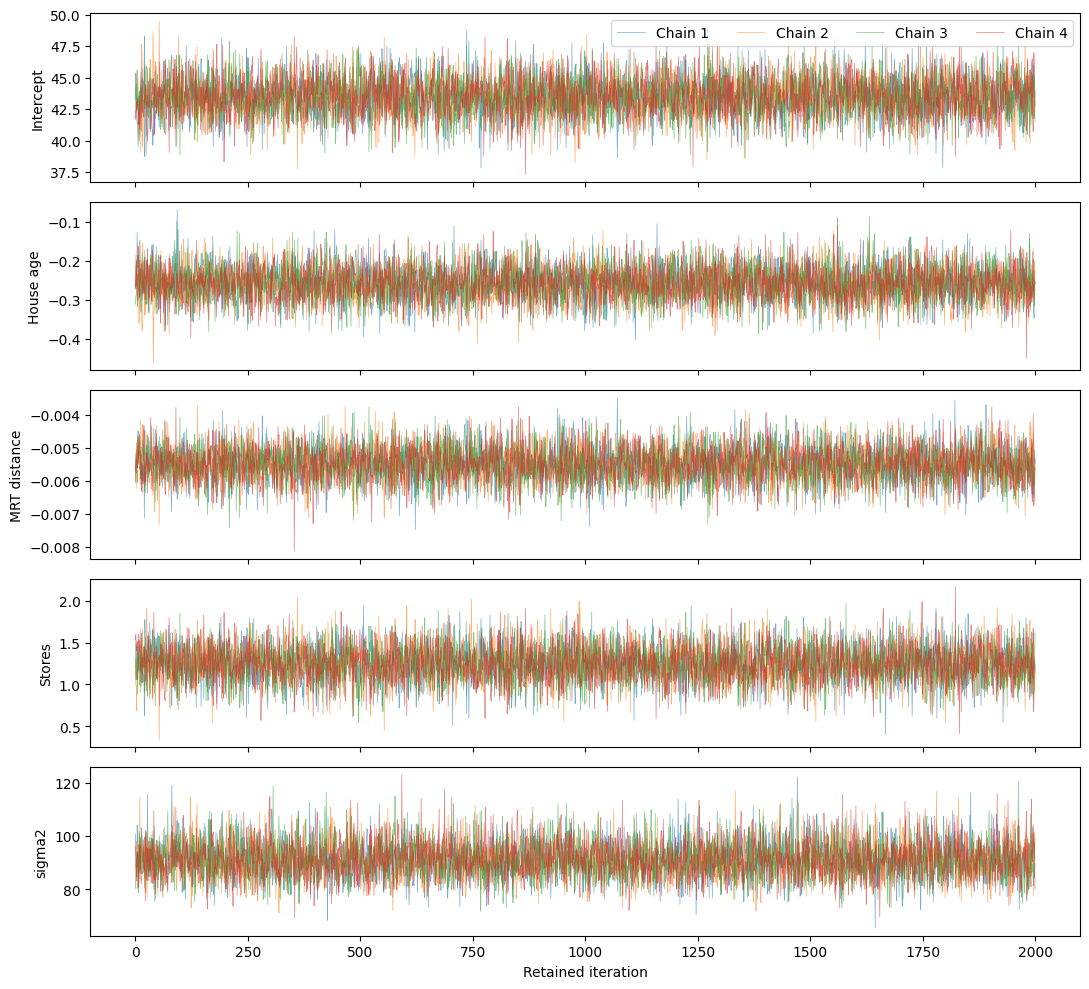

In [17]:
import matplotlib.pyplot as plt

# Collect retained draws for all five parameters
traces = [beta_chains[:, :, j] for j in range(p)]
traces.append(sigma2_chains)

labels = ["Intercept", "House age", "MRT distance", "Stores", "sigma2"]

# Plot all chains separately for each parameter
fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)

for ax, draws, label in zip(axes, traces, labels):
    for chain in range(draws.shape[0]):
        ax.plot(
            draws[chain],
            alpha=0.6,
            linewidth=0.5,
            label=f"Chain {chain + 1}"
        )
    ax.set_ylabel(label)

axes[0].legend(loc="upper right", ncol=4)
axes[-1].set_xlabel("Retained iteration")
plt.tight_layout()
plt.show()

<a id="step-11"></a>
## Step 11 - Predict with MCMC draws and compare all three methods

### 11.1 Generate MCMC posterior predictive draws

**Objective.** Use the retained Gibbs parameter pairs to predict the same 83 test properties.

For each retained draw `s` and test observation `i`,

$$
\eta_i^{(s)}=x_i^\top\beta^{(s)},
\qquad
y_i^{(s)}=\eta_i^{(s)}
+\sqrt{\sigma^{2(s)}}\,z_i^{(s)},
\qquad z_i^{(s)}\sim N(0,1).
$$

The matrix `conditional_means = mcmc_beta @ X_test.T` has shape `(8000, 83)`. Averaging it over draws estimates the predictive mean of each property. Adding independent observation noise conditional on each parameter pair gives predictive draws of the same shape; columnwise quantiles give the intervals.

> **Tip - Preserve paired draws.** The variance multiplying row `s` must be the variance paired with coefficient row `s`. The two parameters are part of one joint posterior draw.

> **Tip - Means and intervals use different calculations.** The point prediction averages `conditional_means` without simulated observation noise. Predictive intervals use `mcmc_pred_samples`, which includes that noise.


In [18]:
# Compute conditional mean predictions for all posterior draws
conditional_means = mcmc_beta @ X_test.T
mcmc_pred_mean = conditional_means.mean(axis=0)

# Generate predictive draws using paired beta and variance samples
pred_rng = np.random.default_rng(2026)
mcmc_pred_samples = (
    conditional_means
    + np.sqrt(mcmc_sigma2)[:, None]
    * pred_rng.standard_normal(conditional_means.shape)
)

# Compute a 95% predictive interval for each test observation
mcmc_lower, mcmc_upper = np.quantile(
    mcmc_pred_samples, [0.025, 0.975], axis=0
)

# Evaluate point predictions and predictive intervals
y_true = np.asarray(y_test).reshape(-1)
mcmc_errors = y_true - mcmc_pred_mean
mcmc_covered = (y_true >= mcmc_lower) & (y_true <= mcmc_upper)

print(f"MCMC MAE: {np.mean(np.abs(mcmc_errors)):.4f}")
print(f"MCMC RMSE: {np.sqrt(np.mean(mcmc_errors ** 2)):.4f}")
print(f"MCMC coverage: {mcmc_covered.mean():.2%}")
print(f"MCMC mean interval width: {np.mean(mcmc_upper - mcmc_lower):.4f}")

MCMC MAE: 5.6320
MCMC RMSE: 7.6731
MCMC coverage: 96.39%
MCMC mean interval width: 37.6886


### 11.2 Apply identical evaluation rules

**Objective.** Compare analytical calculations, direct sampling, and Gibbs MCMC using MAE, RMSE, empirical coverage, and mean interval width on the same test set.

| Method | Parameter calculation | Predictive interval calculation |
| --- | --- | --- |
| Analytical | Closed-form posterior and predictive means | Predictive t quantiles |
| Direct sampling | Independent paired draws from the joint posterior | Quantiles of simulated new outcomes |
| Gibbs MCMC | Full conditional updates producing a Markov chain | Quantiles of simulated new outcomes |

**What is held fixed:** the selected predictors, training/test split, likelihood, prior, and evaluation definitions.

**What changes:** the route used to calculate posterior and predictive quantities, and the resulting Monte Carlo approximation error.

> **Tip - Same model, different computation.** This is not a comparison of three different prior choices or three different regression models. Agreement is expected because all three methods target the same posterior.

> **Tip - Agreement is not an efficiency benchmark.** Direct sampling uses 2,000 paired draws, while Gibbs uses 8,000 retained paired draws plus discarded iterations. This notebook does not perform an equal-budget timing or computational-efficiency comparison.


In [19]:
import pandas as pd

# Generate predictions from the original direct posterior samples
direct_means = beta_samples @ X_test.T
direct_pred_mean = direct_means.mean(axis=0)

direct_rng = np.random.default_rng(2027)
direct_pred_samples = (
    direct_means
    + np.sqrt(sigma2_samples)[:, None]
    * direct_rng.standard_normal(direct_means.shape)
)
direct_lower, direct_upper = np.quantile(
    direct_pred_samples, [0.025, 0.975], axis=0
)

# Apply identical evaluation rules to all three methods
def evaluate_prediction(pred_mean, lo, hi):
    errors = y_true - pred_mean
    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "Coverage (%)": 100 * np.mean((y_true >= lo) & (y_true <= hi)),
        "Mean interval width": np.mean(hi - lo),
    }

comparison = pd.DataFrame({
    "Analytical": evaluate_prediction(y_pred_mean, lower, upper),
    "Direct sampling": evaluate_prediction(
        direct_pred_mean, direct_lower, direct_upper
    ),
    "Gibbs MCMC": evaluate_prediction(
        mcmc_pred_mean, mcmc_lower, mcmc_upper
    ),
}).T

print(comparison.round(4).to_string())

                    MAE    RMSE  Coverage (%)  Mean interval width
Analytical       5.6319  7.6734       96.3855              37.7424
Direct sampling  5.6353  7.6757       96.3855              37.7311
Gibbs MCMC       5.6320  7.6731       96.3855              37.6886


### 11.3 Interpret the final results

The retained comparison table gives MAE values near 5.63, RMSE values near 7.67, coverage of 80/83 observations, and mean interval widths near 37.7 for all three methods.

The evidence supports three conclusions:

1. **Numerical agreement:** sample-based summaries and predictions closely match analytical calculations for the same conjugate posterior.
2. **Improved point predictions relative to the selected baseline:** the Bayesian model reduces MAE from about 10.92 to 5.63 and RMSE from about 13.11 to 7.67 on this split.
3. **Observation noise dominates the fitted predictive width:** the noise-only reference in Step 8 is already close to the full interval width.

Small differences between the sampling methods are expected from finite random draws. Matching coverage percentages means matching coverage counts; it does not by itself establish that exactly the same individual observations were covered.


**Primary documentation:**

- [UCI Real Estate Valuation dataset](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set): variables, target units, and dataset attribution.
- [SciPy inverse-gamma distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.invgamma.html): shape/scale convention.
- [SciPy Student t distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html): `loc`, `scale`, `ppf`, and equal-tailed intervals.
- [NumPy Cholesky factorization](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cholesky.html): lower-triangular matrix factor.
- [ArviZ summary diagnostics](https://python.arviz.org/en/stable/api/generated/arviz.summary.html): diagnostic output columns.
- [Stan posterior analysis](https://mc-stan.org/docs/reference-manual/analysis.html): R-hat, effective sample size, and Monte Carlo precision.
